In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

filename = "dictionary.txt"

rows = []


Всего строк: 5100127

Результаты анализа:
PRTF: 1795884 строк (35.21%)
NOUN: 1415653 строк (27.76%)
VERB: 419073 строк (8.22%)
ADJF: 254143 строк (4.98%)
ADJF femn: 235549 строк (4.62%)
ADJF neut: 201911 строк (3.96%)
ADJF masc: 168250 строк (3.30%)
ADJF plur: 168245 строк (3.30%)
GRND: 70943 строк (1.39%)
PRTS: 68618 строк (1.35%)
ADJF inan: 67298 строк (1.32%)
ADJF anim: 67288 строк (1.32%)
COMP: 38624 строк (0.76%)
INFN: 32374 строк (0.63%)
ADJS: 31356 строк (0.61%)
COMP Cmp2: 14348 строк (0.28%)
ADJS neut: 10260 строк (0.20%)
ADJS masc: 9178 строк (0.18%)
ADJS plur: 9175 строк (0.18%)
ADJS femn: 9166 строк (0.18%)
COMP V-ej: 7177 строк (0.14%)
ADVB: 4056 строк (0.08%)
INTJ: 302 строк (0.01%)
NPRO: 243 строк (0.00%)
CONJ: 185 строк (0.00%)
PRCL: 131 строк (0.00%)
PREP: 126 строк (0.00%)
PRED: 80 строк (0.00%)
NUMR: 70 строк (0.00%)
NUMR nomn: 53 строк (0.00%)
NUMR datv: 53 строк (0.00%)
NUMR gent: 51 строк (0.00%)
NUMR loct: 50 строк (0.00%)
NUMR accs: 48 строк (0.00%)
NUMR ablt: 4

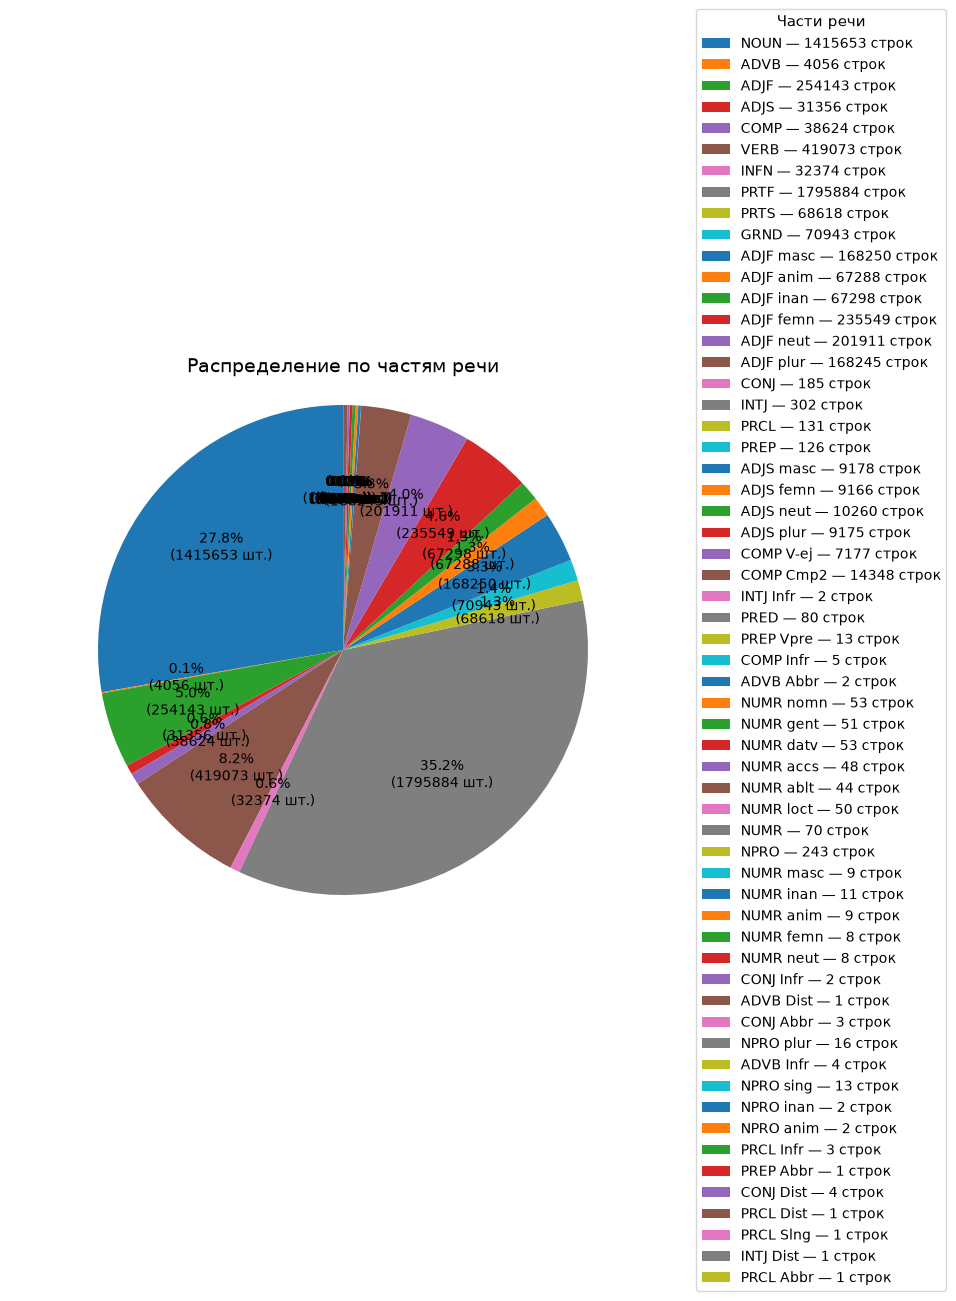

In [2]:
# Прочитаем файл и определим как заменять подписи частей речи выводим статистику

with open(filename, 'r', encoding='utf-8') as f:
    for line in f:
        line = line.strip()

        if not line or line.isdigit():
            continue

        columns = line.split("\t")

        if len(columns) >= 2:
            word = columns[0].strip()
            tags = columns[1].strip()
            rows.append((word, tags))

if not rows:
    print("Данные не найдены. Проверь формат input.txt.")
    raise SystemExit

df = pd.DataFrame(rows, columns=["Слово", "Признаки"])

df["Часть речи"] = df["Признаки"].str.split(",").str[0]

counts = Counter(df["Часть речи"])
total = sum(counts.values())

print(f"\nВсего строк: {total}\n")
print("Результаты анализа:")

for part, count in counts.most_common():
    percent = count / total * 100
    print(f"{part}: {count} строк ({percent:.2f}%)")

# Сводная таблица

summary = pd.DataFrame([
    {
        "Часть речи": part,
        "Количество": count,
        "Процент": round(count / total * 100, 2)
    }
    for part, count in counts.most_common()
])

fig, ax = plt.subplots(figsize=(12, 7))

labels = [
    f"{part} — {count} строк"
    for part, count in counts.items()
]

values = list(counts.values())

def show_values(pct):
    count = round(pct * total / 100)
    return f"{pct:.1f}%\n({count} шт.)"

wedges, texts, autotexts = ax.pie(
    values,
    labels=None,
    autopct=show_values,
    startangle=90,
    pctdistance=0.65,
    textprops={"fontsize": 10}
)

ax.legend(
    wedges,
    labels,
    title="Части речи",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=10,
    title_fontsize=11
)

ax.set_title("Распределение по частям речи", fontsize=14)
ax.axis("equal")

# Оставляем место справа для легенды
plt.subplots_adjust(right=0.68)

plt.show()
